In [11]:

import matplotlib.pyplot as plt
import networkx as nx
import heapq
from collections import deque

print("Libraries imported successfully!")


Libraries imported successfully!


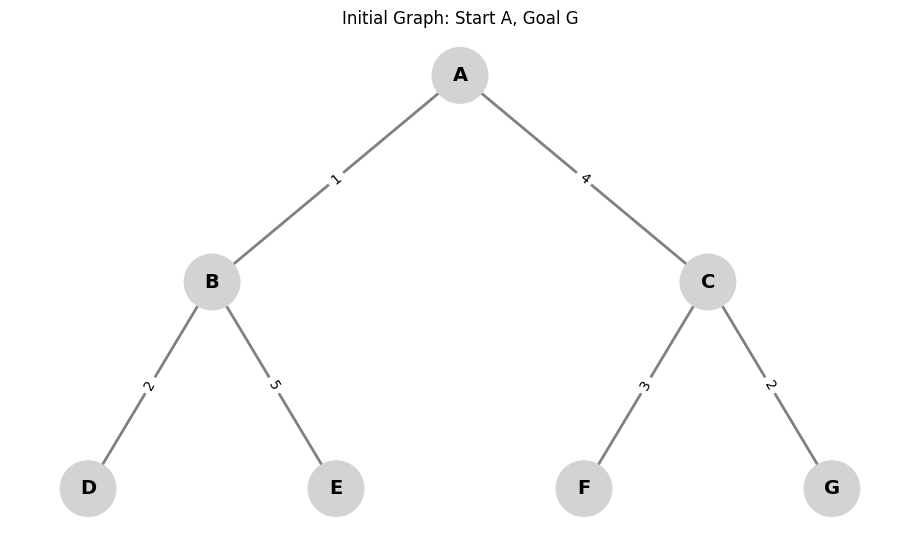

In [12]:

# Graph connections: neighbor order matters
graph = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F', 'G'],
    'D': [],
    'E': [],
    'F': [],
    'G': []
}

# Edge costs for Uniform-Cost Search
costs = {
    ('A', 'B'): 1,
    ('A', 'C'): 4,
    ('B', 'D'): 2,
    ('B', 'E'): 5,
    ('C', 'F'): 3,
    ('C', 'G'): 2
}

# Fixed positions keep the graph easy to read
positions = {
    'A': (0, 2),
    'B': (-1, 1),
    'C': (1, 1),
    'D': (-1.5, 0),
    'E': (-0.5, 0),
    'F': (0.5, 0),
    'G': (1.5, 0)
}

def draw_graph(visited=None, path=None, title="Search Graph"):
    if visited is None:
        visited = []
    if path is None:
        path = []

    G = nx.Graph()

    for node, neighbors in graph.items():
        G.add_node(node)
        for neighbor in neighbors:
            G.add_edge(node, neighbor,
                       weight=costs[(node, neighbor)])

    visited_set = set(visited)
    path_edges = set(zip(path, path[1:]))

    node_colors = []
    for node in G.nodes():
        if node in path:
            node_colors.append("lightgreen")
        elif node in visited_set:
            node_colors.append("lightskyblue")
        else:
            node_colors.append("lightgray")

    edge_colors = []
    for u, v in G.edges():
        if (u, v) in path_edges or (v, u) in path_edges:
            edge_colors.append("green")
        else:
            edge_colors.append("gray")

    plt.figure(figsize=(9, 5))

    nx.draw(
        G, positions,
        with_labels=True,
        node_color=node_colors,
        edge_color=edge_colors,
        node_size=1600,
        font_size=14,
        font_weight="bold",
        width=2
    )

    edge_labels = {
        (u, v): data["weight"]
        for u, v, data in G.edges(data=True)
    }
    nx.draw_networkx_edge_labels(
        G, positions, edge_labels=edge_labels
    )

    plt.title(title)
    plt.axis("off")
    plt.show()

draw_graph(title="Initial Graph: Start A, Goal G")


BFS Traversal: ['A', 'B', 'C', 'D', 'E', 'F', 'G']
Path to Goal: A -> C -> G


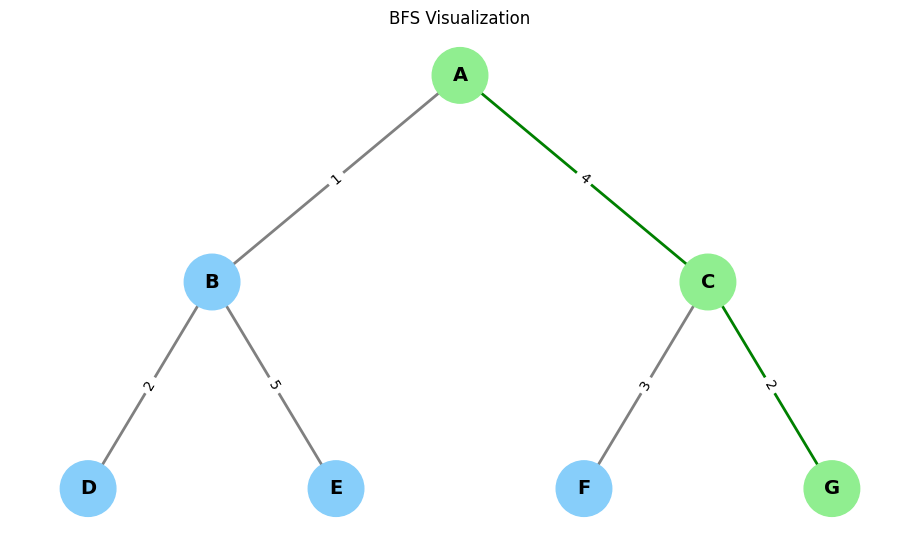

In [13]:

def bfs(start, goal):
    queue = deque([(start, [start])])
    visited = []
    discovered = {start}

    while queue:
        node, path = queue.popleft()
        visited.append(node)

        if node == goal:
            return visited, path

        for neighbor in graph[node]:
            if neighbor not in discovered:
                discovered.add(neighbor)
                queue.append((neighbor, path + [neighbor]))

    return visited, None


visited, path = bfs('A', 'G')

print("BFS Traversal:", visited)
print("Path to Goal:", " -> ".join(path))
draw_graph(visited, path, "BFS Visualization")


DFS Traversal: ['A', 'B', 'D', 'E', 'C', 'F', 'G']
Path to Goal: A -> C -> G


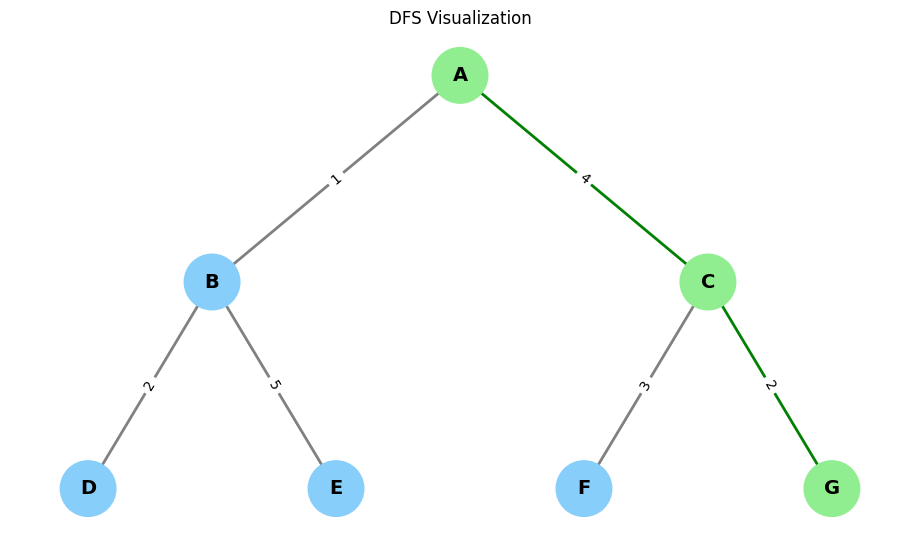

In [14]:

def dfs(start, goal):
    stack = [(start, [start])]
    visited = []
    discovered = {start}

    while stack:
        node, path = stack.pop()

        if node in visited:
            continue

        visited.append(node)

        if node == goal:
            return visited, path

        # Reverse the order so B is explored before C
        for neighbor in reversed(graph[node]):
            if neighbor not in discovered:
                discovered.add(neighbor)
                stack.append((neighbor, path + [neighbor]))

    return visited, None


visited, path = dfs('A', 'G')

print("DFS Traversal:", visited)
print("Path to Goal:", " -> ".join(path))
draw_graph(visited, path, "DFS Visualization")


DLS Traversal: ['A', 'B', 'D', 'E', 'C', 'F', 'G']
Depth Limit: 2
Path to Goal: A -> C -> G


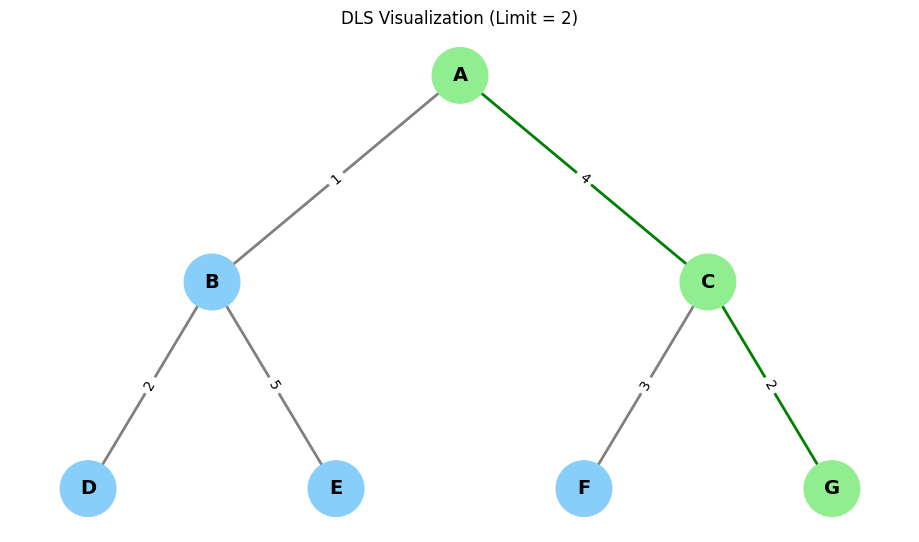

In [15]:

def dls(start, goal, limit):
    visited = []

    def search(node, path, depth):
        visited.append(node)

        if node == goal:
            return path

        if depth == limit:
            return None

        for neighbor in graph[node]:
            if neighbor not in path:
                result = search(
                    neighbor,
                    path + [neighbor],
                    depth + 1
                )

                if result is not None:
                    return result

        return None

    path = search(start, [start], 0)
    return visited, path


visited, path = dls('A', 'G', 2)

print("DLS Traversal:", visited)
print("Depth Limit:", 2)
print("Path to Goal:", " -> ".join(path) if path else "Goal not found")
draw_graph(visited, path, "DLS Visualization (Limit = 2)")


Depth limit 0: ['A']
Depth limit 1: ['A', 'B', 'C']
Depth limit 2: ['A', 'B', 'D', 'E', 'C', 'F', 'G']
IDDFS Final Traversal: ['A', 'B', 'D', 'E', 'C', 'F', 'G']
Path to Goal: A -> C -> G


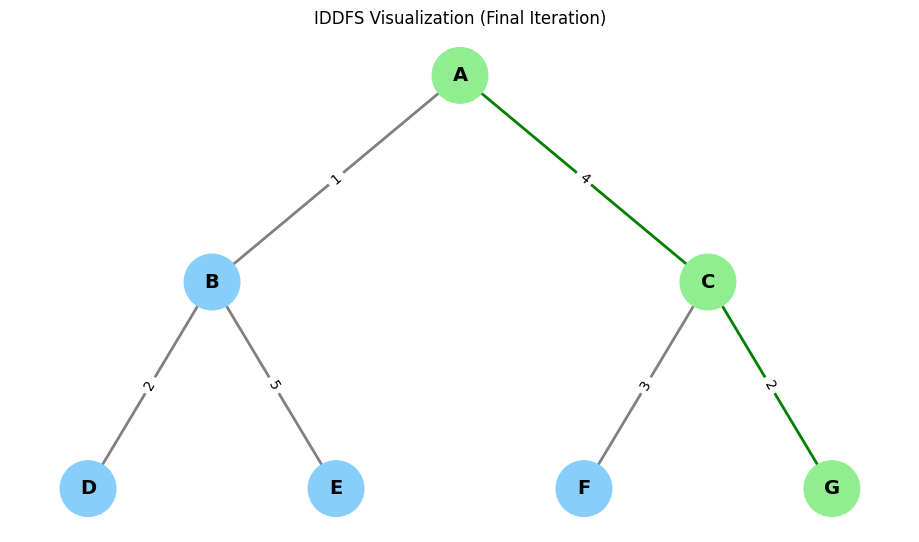

In [16]:

def iddfs(start, goal):
    all_iterations = []

    def limited_search(limit):
        visited = []

        def search(node, path, depth):
            visited.append(node)

            if node == goal:
                return path

            if depth == limit:
                return None

            for neighbor in graph[node]:
                if neighbor not in path:
                    result = search(
                        neighbor,
                        path + [neighbor],
                        depth + 1
                    )

                    if result is not None:
                        return result

            return None

        path = search(start, [start], 0)
        return visited, path

    for limit in range(len(graph)):
        visited, path = limited_search(limit)
        all_iterations.append((limit, visited, path))

        if path is not None:
            return all_iterations, visited, path

    return all_iterations, [], None


iterations, visited, path = iddfs('A', 'G')

for limit, iteration_visited, iteration_path in iterations:
    print(f"Depth limit {limit}: {iteration_visited}")

print("IDDFS Final Traversal:", visited)
print("Path to Goal:", " -> ".join(path))
draw_graph(visited, path, "IDDFS Visualization (Final Iteration)")


UCS Expansion Order: ['A', 'B', 'D', 'C', 'E', 'G']
Path to Goal: A -> C -> G
Total Path Cost: 6


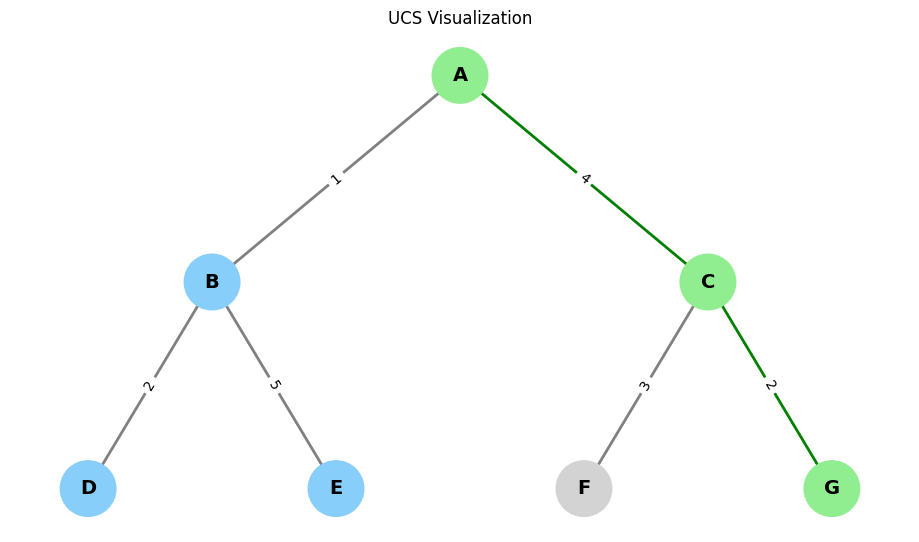

In [17]:

def ucs(start, goal):
    counter = 0
    priority_queue = [(0, counter, start, [start])]
    best_cost = {start: 0}
    visited = []

    while priority_queue:
        cost, _, node, path = heapq.heappop(priority_queue)

        # Ignore outdated, more expensive entries
        if cost != best_cost.get(node):
            continue

        visited.append(node)

        if node == goal:
            return visited, path, cost

        for neighbor in graph[node]:
            edge_cost = costs[(node, neighbor)]
            new_cost = cost + edge_cost

            if new_cost < best_cost.get(neighbor, float('inf')):
                best_cost[neighbor] = new_cost
                counter += 1
                heapq.heappush(
                    priority_queue,
                    (new_cost, counter, neighbor, path + [neighbor])
                )

    return visited, None, float('inf')


visited, path, total_cost = ucs('A', 'G')

print("UCS Expansion Order:", visited)
print("Path to Goal:", " -> ".join(path))
print("Total Path Cost:", total_cost)
draw_graph(visited, path, "UCS Visualization")


In [18]:

results = []

visited, path = bfs('A', 'G')
results.append(("BFS", visited, path, None))

visited, path = dfs('A', 'G')
results.append(("DFS", visited, path, None))

visited, path = dls('A', 'G', 2)
results.append(("DLS", visited, path, None))

iterations, visited, path = iddfs('A', 'G')
results.append(("IDDFS", visited, path, None))

visited, path, total_cost = ucs('A', 'G')
results.append(("UCS", visited, path, total_cost))

for name, visited, path, cost in results:
    print(f"\n{name}")
    print("Visited:", " -> ".join(visited))
    print("Path:", " -> ".join(path) if path else "Not found")

    if cost is not None:
        print("Total cost:", cost)



BFS
Visited: A -> B -> C -> D -> E -> F -> G
Path: A -> C -> G

DFS
Visited: A -> B -> D -> E -> C -> F -> G
Path: A -> C -> G

DLS
Visited: A -> B -> D -> E -> C -> F -> G
Path: A -> C -> G

IDDFS
Visited: A -> B -> D -> E -> C -> F -> G
Path: A -> C -> G

UCS
Visited: A -> B -> D -> C -> E -> G
Path: A -> C -> G
Total cost: 6


In [21]:


import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

def animate_search(order, path, title):
    G = nx.Graph()

    for node, neighbors in graph.items():
        G.add_node(node)
        for neighbor in neighbors:
            G.add_edge(
                node, neighbor,
                weight=costs[(node, neighbor)]
            )

    if path is None:
        path = []

    path_edges = set(zip(path, path[1:]))

    fig, ax = plt.subplots(figsize=(9, 5))

    # One frame per visited node, plus one final frame
    total_frames = len(order) + 1

    def update(frame):
        ax.clear()

        if frame < len(order):
            visited_now = order[:frame + 1]
            current_node = order[frame]
            finished = False
        else:
            visited_now = order
            current_node = None
            finished = True

        node_colors = []

        for node in G.nodes():
            if finished and node in path:
                node_colors.append("lightgreen")
            elif node == current_node:
                node_colors.append("orange")
            elif node in visited_now:
                node_colors.append("lightskyblue")
            else:
                node_colors.append("lightgray")

        edge_colors = []

        for u, v in G.edges():
            if finished and (
                (u, v) in path_edges or
                (v, u) in path_edges
            ):
                edge_colors.append("green")
            else:
                edge_colors.append("gray")

        nx.draw(
            G, positions, ax=ax,
            with_labels=True,
            node_color=node_colors,
            edge_color=edge_colors,
            node_size=1600,
            font_size=14,
            font_weight="bold",
            width=2
        )

        edge_labels = {
            (u, v): data["weight"]
            for u, v, data in G.edges(data=True)
        }

        nx.draw_networkx_edge_labels(
            G, positions,
            edge_labels=edge_labels,
            ax=ax
        )

        if finished:
            if path:
                ax.set_title(
                    f"{title} - Goal Found!\n"
                    f"Final Path: {' -> '.join(path)}"
                )
            else:
                ax.set_title(f"{title} - Goal Not Found")
        else:
            ax.set_title(
                f"{title} | Visiting: {current_node}\n"
                f"Traversal: {' -> '.join(visited_now)}"
            )

        ax.axis("off")

    animation = FuncAnimation(
        fig,
        update,
        frames=total_frames,
        interval=1000,
        repeat=False
    )

    plt.close(fig)
    display(HTML(animation.to_jshtml()))




In [23]:
visited, path = bfs('A', 'G')
print("BFS Traversal:", visited)
print("Goal Path:", " -> ".join(path))
animate_search(visited, path, "Breadth-First Search (BFS)")

BFS Traversal: ['A', 'B', 'C', 'D', 'E', 'F', 'G']
Goal Path: A -> C -> G


In [24]:

visited, path = dfs('A', 'G')

print("DFS Traversal:", visited)
print("Goal Path:", " -> ".join(path))

animate_search(visited, path, "Depth-First Search (DFS)")


DFS Traversal: ['A', 'B', 'D', 'E', 'C', 'F', 'G']
Goal Path: A -> C -> G


In [28]:

visited, path = dls('A', 'G', 2)

print("DLS Traversal:", visited)
print("Depth Limit:", 2)
print("Goal Path:", " -> ".join(path) if path else "Not found")

animate_search(visited, path, "Depth-Limited Search (DLS)")


DLS Traversal: ['A', 'B', 'D', 'E', 'C', 'F', 'G']
Depth Limit: 2
Goal Path: A -> C -> G


In [26]:

iterations, visited, path = iddfs('A', 'G')

for limit, iteration_visited, iteration_path in iterations:
    print(f"Depth limit {limit}: {iteration_visited}")

print("Final Goal Path:", " -> ".join(path))

animate_search(visited, path, "Iterative Deepening DFS (IDDFS)")


Depth limit 0: ['A']
Depth limit 1: ['A', 'B', 'C']
Depth limit 2: ['A', 'B', 'D', 'E', 'C', 'F', 'G']
Final Goal Path: A -> C -> G


In [27]:

visited, path, total_cost = ucs('A', 'G')

print("UCS Expansion Order:", visited)
print("Goal Path:", " -> ".join(path))
print("Total Cost:", total_cost)

animate_search(visited, path, "Uniform-Cost Search (UCS)")


UCS Expansion Order: ['A', 'B', 'D', 'C', 'E', 'G']
Goal Path: A -> C -> G
Total Cost: 6
